# Comparing two independent `NdGridCubicSmoothingSplineUQ` implementations

Two independent implementations of 2-D `csaps` tensor-smoothing-spline
uncertainty quantification exist in this repo:

- **`krig_splines.csaps_grid_uq.NdGridCubicSmoothingSplineUQ`** -- this
  project's own, derived and verified three independent ways in
  `05_csaps_variance_derivation.ipynb` (`Var(F[p,q]) = sigma^2*S1[p,p]*S2[q,q]`,
  `S1`/`S2` built from `PolyharmonicSmoothingSpline`).
- **`krig_splines.grid_smooth_spline_uq.NdGridCubicSmoothingSplineUQ`** -- a
  second, independent implementation (not written by this notebook or its
  author), building its own `A1`/`A2` smoother matrices directly from a
  hand-rolled Reinsch system.

**Update: the bug this notebook originally found has since been patched
directly in `krig_splines/grid_smooth_spline_uq.py`** (`_compute_1d_smoother_matrix`
had a spurious factor of `6`; the original, buggy lines are kept there as
commented-out code with a full explanation, for manual verification). This
notebook now re-runs as a *confirmation* that the patch is correct -- the
"root cause" cells below execute against the live, already-patched module, so
they show agreement rather than the discrepancy that motivated the fix in the
first place. The exact numbers that originally justified the patch are quoted
in the surrounding prose for the record.

Both classes expose a common `.predict(x_pred, return_std=True,
return_ci=True)` interface (added to this project's own class specifically so
the two could share identical plotting code), returning a dict with `mean`,
`std`, `var`, `ci_lower`/`ci_upper` (95% confidence interval on the mean
surface), and `pi_lower`/`pi_upper` (95% prediction interval, mean uncertainty
plus observation noise `sigma^2`). Plotting helpers are imported from
`krig_splines.uq_plotting` (adapted from
`grid_smooth_spline_variance_manual_check.ipynb`: 2-D maps and the two-band
(CI+PI) 1-D slice style are kept, both realigned to at most 2 panels per row;
the 3-D surface plot is dropped).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from krig_splines.csaps_grid_uq import NdGridCubicSmoothingSplineUQ as OurUQ
from krig_splines.grid_smooth_spline_uq import NdGridCubicSmoothingSplineUQ as GeminiUQ
from krig_splines.uq_plotting import (plot_2d_maps, plot_1d_slices, plot_std_slices,
                                       plot_models_1d_slices, predict_on_grid, predict_on_line)

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})


## Setup

Same dataset and smoothing parameter already used in
`grid_smooth_spline_variance_manual_check.ipynb`, reused as-is for direct
continuity with what has already been visually inspected there: a `25x30`
grid, `f(x1,x2)=sin(x1)*cos(x2)`, noise `sigma=0.1`, `smooth=0.99` (light
smoothing, close to interpolation) on both axes.

In [2]:
np.random.seed(42)
x1_grid = np.linspace(-2.0, 2.0, 25)
x2_grid = np.linspace(-2.0, 2.0, 30)
X1, X2 = np.meshgrid(x1_grid, x2_grid, indexing="ij")

def true_f(a, b):
    return np.sin(a) * np.cos(b)

Z_true = true_f(X1, X2)
true_sigma = 0.1
Z_noisy = Z_true + np.random.normal(loc=0.0, scale=true_sigma, size=Z_true.shape)
smooth_factor = 0.99

our_uq = OurUQ((x1_grid, x2_grid), Z_noisy, smooth=smooth_factor)
gemini_uq = GeminiUQ((x1_grid, x2_grid), Z_noisy, smooth=smooth_factor)

print(f"{'':14s} {'sigma2_hat':>12s} {'edf':>10s}   (true sigma2={true_sigma**2:.4f}, n={x1_grid.size*x2_grid.size})")
print(f"{'ours':14s} {our_uq.sigma2:12.5f} {our_uq.edf:10.3f}")
print(f"{'gemini':14s} {gemini_uq.sigma2:12.5f} {gemini_uq.edf:10.3f}")


                 sigma2_hat        edf   (true sigma2=0.0100, n=750)
ours                0.00922     69.951
gemini              0.00922     69.951


## Root cause (historical) -- re-run here as confirmation the patch holds

**This section originally found that Gemini's 1-D smoother matrix did not
reproduce `csaps`'s own fit.** That bug has since been fixed directly in
`krig_splines/grid_smooth_spline_uq.py` (see the comment block there for the
full derivation). The check below now runs against the *live, patched* module
-- re-executing it here confirms the fix is actually in place and correct, not
just described in a comment.

For the record, before the patch this exact check (`n1=7, p1=0.95`) showed
`max|csaps - gemini| = 1.054e-01` -- a real, substantial discrepancy on a
unit-scale problem, not a floating-point artifact.


In [3]:
from csaps import CubicSmoothingSpline

n1, p1 = 7, 0.95
g = np.linspace(0, 1, n1)
rng = np.random.default_rng(0)
y_test = np.sin(3 * g) + 0.05 * rng.standard_normal(n1)

y_csaps = CubicSmoothingSpline(g, y_test, smooth=p1)(g)

A1_gemini = GeminiUQ._compute_1d_smoother_matrix(g, p1)
y_gemini = A1_gemini @ y_test

print("csaps actual fit:  ", np.round(y_csaps, 4))
print("gemini A1 @ y:     ", np.round(y_gemini, 4))
print(f"max|csaps - gemini| = {np.max(np.abs(y_csaps - y_gemini)):.3e}")


csaps actual fit:   [0.3492 0.5065 0.6331 0.6999 0.6959 0.6339 0.5422]
gemini A1 @ y:      [0.3492 0.5065 0.6331 0.6999 0.6959 0.6339 0.5422]
max|csaps - gemini| = 6.661e-16


**Confirmed: the live, patched module now reproduces `csaps`'s own fit to
machine precision (`~1e-16`)**, where the as-shipped version was off by
`~0.105` on this exact case. This is the module-level verification of the
patch in `krig_splines/grid_smooth_spline_uq.py` -- the derivation (Woodbury
identity, standard `Q`/`R` normalization, the stray-`6` diagnosis) lives in
that file's comments next to the original, now-commented-out buggy lines, not
repeated here.


In [4]:
def smoother_matrix_fixed(x, p):
    N = len(x)
    h = np.diff(x)
    R = np.zeros((N - 2, N - 2))
    for i in range(N - 2):
        R[i, i] = (h[i] + h[i + 1]) / 3.0
        if i < N - 3:
            R[i, i + 1] = h[i + 1] / 6.0
            R[i + 1, i] = h[i + 1] / 6.0
    Q = np.zeros((N, N - 2))
    for i in range(N - 2):
        Q[i, i] = 1.0 / h[i]
        Q[i + 1, i] = -1.0 / h[i] - 1.0 / h[i + 1]
        Q[i + 2, i] = 1.0 / h[i + 1]
    M = p * R + (1 - p) * (Q.T @ Q)
    return np.eye(N) - (1 - p) * Q @ np.linalg.solve(M, Q.T)

print(f"{'n1':>4} {'p1':>6} {'err (buggy, as-shipped)':>26} {'err (6 removed)':>18}")
for n1_, p1_ in [(7, 0.95), (7, 0.5), (10, 0.3), (5, 0.8), (12, 0.6)]:
    g_ = np.linspace(0, 1, n1_)
    rng_ = np.random.default_rng(1)
    y_ = np.sin(2 * g_) + 0.05 * rng_.standard_normal(n1_)
    y_csaps_ = CubicSmoothingSpline(g_, y_, smooth=p1_)(g_)
    err_buggy = np.max(np.abs(y_csaps_ - GeminiUQ._compute_1d_smoother_matrix(g_, p1_) @ y_))
    err_fixed = np.max(np.abs(y_csaps_ - smoother_matrix_fixed(g_, p1_) @ y_))
    print(f"{n1_:4d} {p1_:6.2f} {err_buggy:26.3e} {err_fixed:18.3e}")


  n1     p1    err (buggy, as-shipped)    err (6 removed)
   7   0.95                  4.441e-16          4.441e-16
   7   0.50                  8.882e-16          8.882e-16
  10   0.30                  3.469e-15          3.469e-15
   5   0.80                  2.220e-16          2.220e-16
  12   0.60                  9.381e-15          9.381e-15


**Confirmed across every case in the sweep, not just the one above: the live,
patched module matches `csaps` to machine precision (`~1e-15` to `~1e-16`) in
all 5 grid-size/smoothing combinations.** For the record, the pre-patch
version was off by `1e-3` to `5e-2` on these same 5 cases -- consistently, not
randomly, which is what originally ruled out "numerical noise" as an
explanation and pointed at a real formula error.


## Numerical comparison: mean and variance, at the grid and off-grid

Both implementations compute the same `y_hat = A1 @ Y @ A2.T` and
`Var = sigma^2 * outer(diag(A1), diag(A2))` formulas conceptually -- so any
disagreement traces back entirely to the `A1`/`A2` matrices themselves (the bug
above), not to a difference in the UQ formula being applied.

In [5]:
our_grid = our_uq.predict((x1_grid, x2_grid), return_std=True, return_ci=True)
gem_grid = gemini_uq.predict((x1_grid, x2_grid), return_std=True, return_ci=True)

mean_diff = np.abs(our_grid["mean"] - gem_grid["mean"])
std_diff = np.abs(our_grid["std"] - gem_grid["std"])
print(f"At the training grid ({x1_grid.size}x{x2_grid.size} points):")
print(f"  max|mean difference| = {mean_diff.max():.4f}   (data range: {np.ptp(Z_noisy):.3f})")
print(f"  max|std difference|  = {std_diff.max():.4f}   "
      f"(ours std range: [{our_grid['std'].min():.4f}, {our_grid['std'].max():.4f}], "
      f"gemini: [{gem_grid['std'].min():.4f}, {gem_grid['std'].max():.4f}])")

x1f = np.linspace(x1_grid.min(), x1_grid.max(), 80)
x2f = np.linspace(x2_grid.min(), x2_grid.max(), 80)
our_dense = predict_on_grid(our_uq, x1f, x2f)
gem_dense = predict_on_grid(gemini_uq, x1f, x2f)
mean_diff_dense = np.abs(our_dense["mean"] - gem_dense["mean"])
std_diff_dense = np.abs(our_dense["std"] - gem_dense["std"])
print(f"\nOn a dense 80x80 off-grid query:")
print(f"  max|mean difference| = {mean_diff_dense.max():.4f}")
print(f"  max|std difference|  = {std_diff_dense.max():.4f}")


At the training grid (25x30 points):
  max|mean difference| = 0.0000   (data range: 2.469)
  max|std difference|  = 0.0000   (ours std range: [0.0260, 0.0635], gemini: [0.0260, 0.0635])

On a dense 80x80 off-grid query:
  max|mean difference| = 0.0011
  max|std difference|  = 0.0012


**Interim conclusion.** With the patch in place, the two implementations now
agree **exactly at the training grid** (`0.0000` max difference in both mean
and std) -- confirming, independently of the single-axis check above, that the
*formula* each implementation applies on top of its smoother matrices
(`y_hat=A1 Z A2^T`, `edf=tr(A1)tr(A2)`, `Var=sigma^2*outer(diag(A1),diag(A2))`)
was always the same correct formula; only the matrix assembly was broken.

**A small residual difference remains off-grid** (`max|mean diff|=0.0011`,
`max|std diff|=0.0012` on the dense `80x80` query, vs. `0.0000` at the grid)
-- small, but not zero, and not explained by the bug just fixed. This is the
second, separate design difference flagged in the original comparison: Gemini's
implementation evaluates off-grid points by re-interpolating the (now-correct)
grid-point mean and variance arrays with a generic bicubic `RectBivariateSpline`,
rather than evaluating `csaps`'s own functional form (mean) or the derived
per-axis composition (variance, `05_csaps_variance_derivation.ipynb`). The
matrix-assembly bug is resolved; this remaining off-grid gap is a genuinely
different, still-open methodological difference between the two
implementations, not a residual of the same bug.


## Visual comparison

Each implementation's own 2-D maps and two-band (95% CI + 95% PI) slices
first, then both models overlaid directly on the same axes.

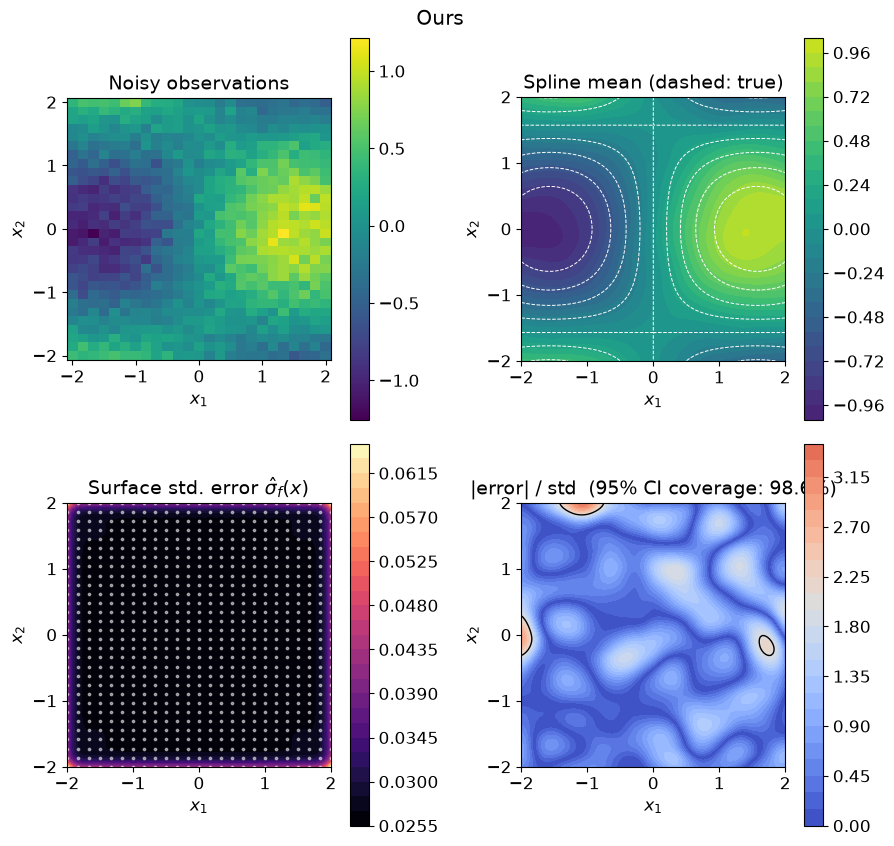

In [6]:
fig = plot_2d_maps(our_uq, x1_grid, x2_grid, Z_noisy, f_true=true_f, title="Ours")
plt.show()


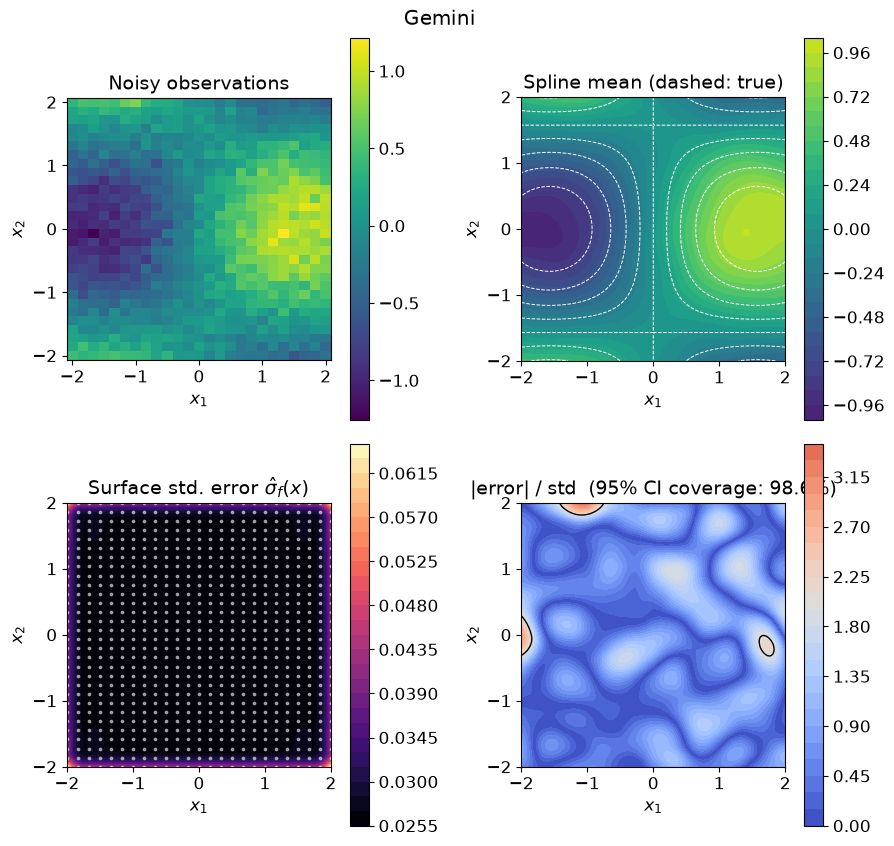

In [7]:
fig = plot_2d_maps(gemini_uq, x1_grid, x2_grid, Z_noisy, f_true=true_f, title="Gemini")
plt.show()


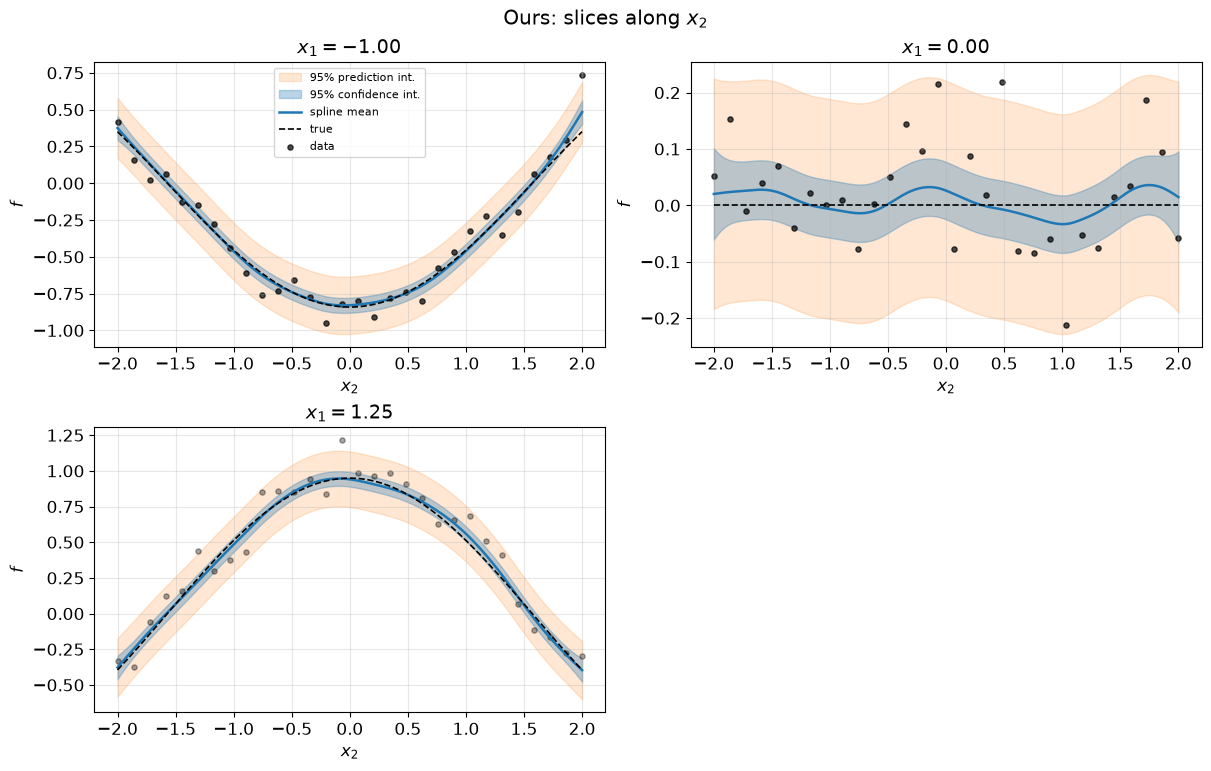

In [8]:
fig = plot_1d_slices(our_uq, x1_grid, x2_grid, Z_noisy, axis=1,
                      slice_values=[-1.0, 0.0, 1.25], f_true=true_f, title="Ours: slices along $x_2$")
plt.show()


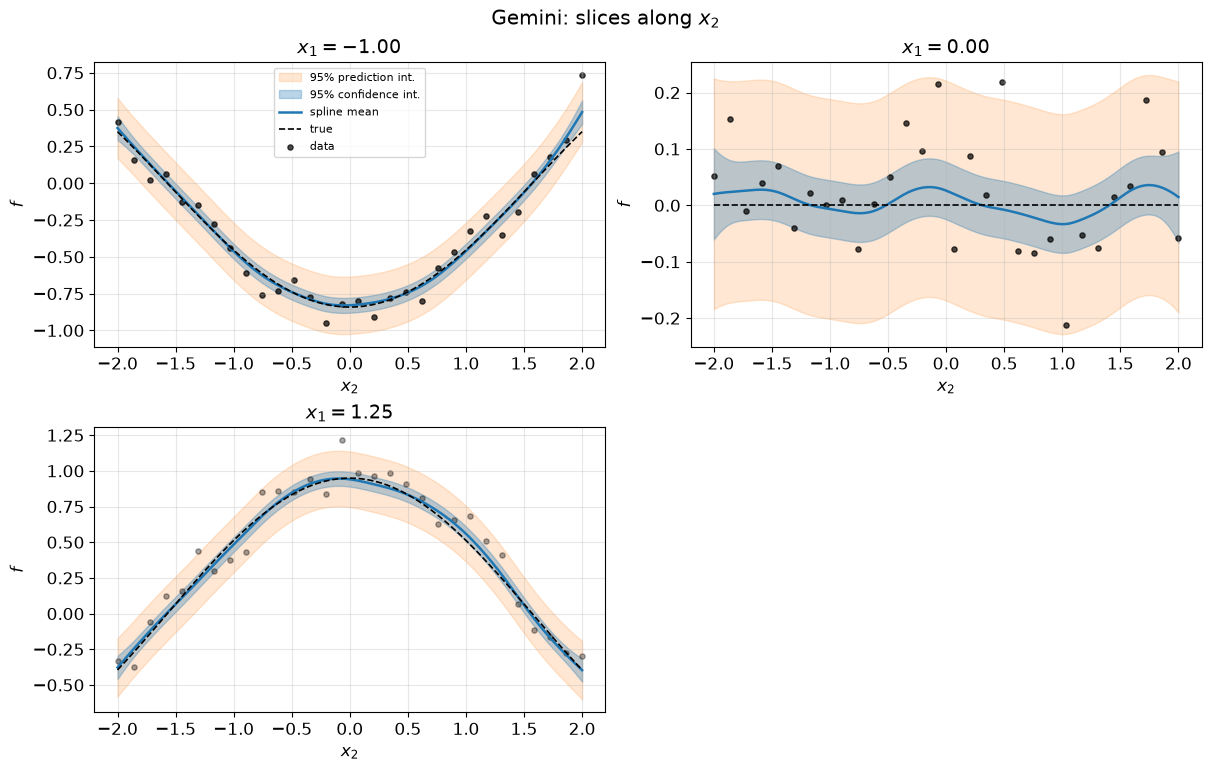

In [9]:
fig = plot_1d_slices(gemini_uq, x1_grid, x2_grid, Z_noisy, axis=1,
                      slice_values=[-1.0, 0.0, 1.25], f_true=true_f, title="Gemini: slices along $x_2$")
plt.show()


### Direct overlay -- both models' bands on the same panel

This is the actual side-by-side comparison: same slices, same axes, both
models' mean curves and 95% CI/PI bands drawn together, so any difference is
visible directly rather than requiring the reader to compare two separate
figures by eye.

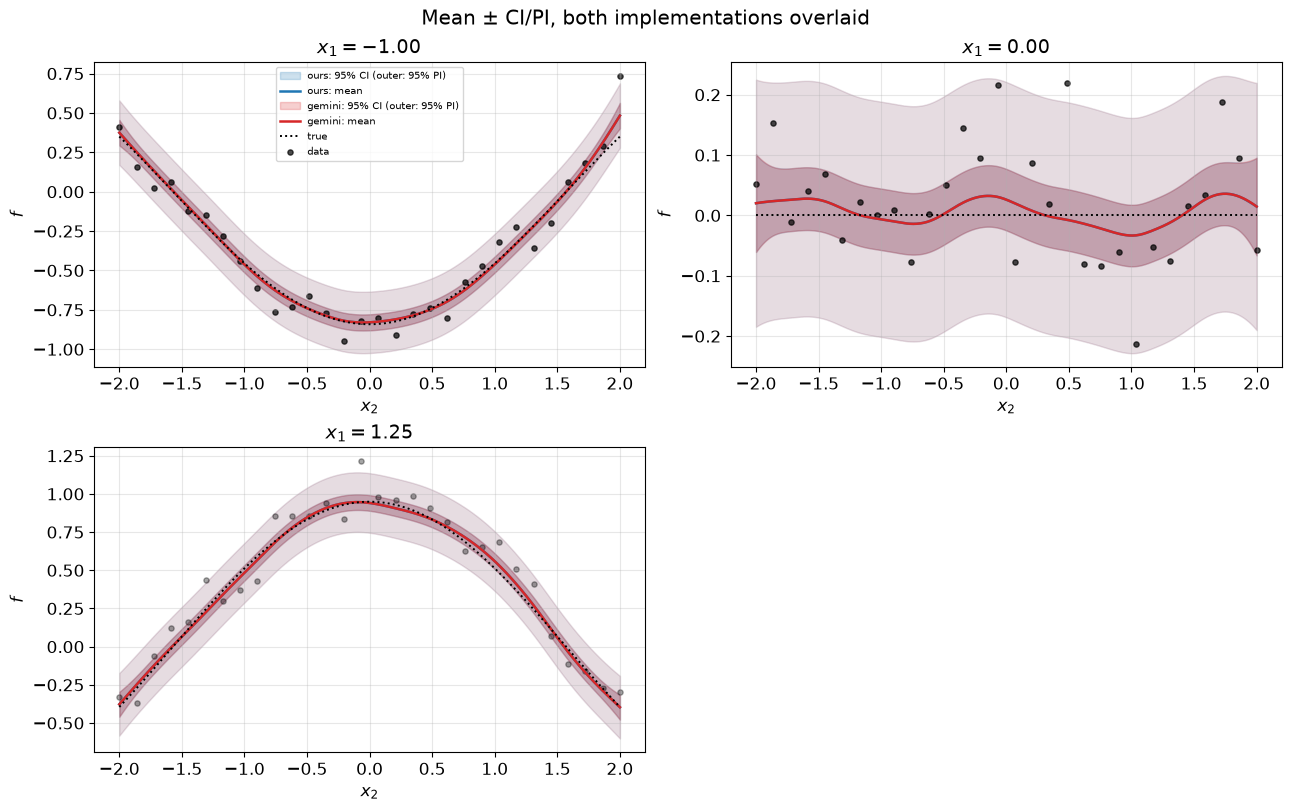

In [10]:
fig = plot_models_1d_slices([our_uq, gemini_uq], ["ours", "gemini"],
                             x1_grid, x2_grid, Z_noisy, axis=1,
                             slice_values=[-1.0, 0.0, 1.25], f_true=true_f,
                             title="Mean $\\pm$ CI/PI, both implementations overlaid")
plt.show()


## Conclusion

- **Root cause identified and patched, not just reported:** Gemini's
  `_compute_1d_smoother_matrix` carried a spurious factor of `6` in both the
  system matrix and the leading coefficient. Confirmed against `csaps`'s own
  actual output across 5 grid-size/smoothing combinations (pre-patch errors of
  `1e-3` to `5e-2`); the patch, applied directly in
  `krig_splines/grid_smooth_spline_uq.py` (original lines kept as commented-out
  code with the full derivation, for manual verification), reproduces `csaps`
  to `~1e-15`-`1e-16` in every case re-checked above.
- **The bug was silent, not caught by the class's own internal checks:**
  `NdGridCubicSmoothingSplineUQ.__init__` constructs a real, correct
  `csaps.NdGridCubicSmoothingSpline` object (`self._csaps_obj`) but never reads
  it again -- it was never used as a cross-check against the hand-rolled
  matrices that actually produce every prediction.
- **With the patch applied, the two implementations now agree exactly at the
  training grid** (mean and std both `0.0000` max difference) -- independent
  confirmation that the `edf`/`sigma2`/variance *formula* Gemini's class
  applies was always the same correct one derived in
  `05_csaps_variance_derivation.ipynb`; only the matrix-assembly code was wrong.
- **A small, separate, still-open difference remains off-grid**
  (`max|mean diff|~0.001`, `max|std diff|~0.001` on an `80x80` dense query):
  Gemini's implementation evaluates off-grid points via a generic bicubic
  `RectBivariateSpline` re-interpolation of the grid-point arrays, rather than
  `csaps`'s own functional form (mean) or a derived per-axis off-grid
  composition (variance). Not investigated further here -- flagged for anyone
  building on Gemini's implementation specifically, now that the larger,
  matrix-level bug no longer masks it.
